# Graph Neural Networks on the Eye-disease Image Dataset

This notebook follows the same structure and coding style as the provided `GNN_Image_Simple.ipynb` sample:

1. Load and inspect the image dataset
2. Turn each image representation into a graph with the same grid method: nodes are grid locations, edges connect immediate up/down/left/right neighbors, and self-loop-normalized adjacency is reused for every sample
3. Build graph node features by concatenating image/deep-feature values with row and column positions
4. Train a CNN baseline using pretrained ResNet50 for 20 epochs
5. Extract ResNet50 deep feature maps and feed them into four GNN models: MDGNet, ViG / Visual GNN, GATv2, and SuperGAT
6. Train each GNN for 20 epochs and display loss/accuracy curves, overall accuracy, per-class accuracy, precision, recall, F1-score, confusion matrix, AUC/ROC, training time, and testing time

Dataset: https://www.kaggle.com/datasets/ahsiulkarim/eye-disease-image-dataset

Classes:
- Central Serous Chorioretinopathy (Color Fundus)
- Diabetic Retinopathy
- Disc Edema
- Glaucoma
- Healthy
- Macular Scar
- Myopia
- Pterygium
- Retinal Detachment
- Retinitis Pigmentosa


In [1]:
# If you are running this on a fresh Kaggle/Colab/local environment, uncomment the line below.
# %pip install -q kagglehub torch torchvision torchaudio scikit-learn matplotlib networkx pillow tqdm

import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

torch.manual_seed(0)
np.random.seed(0)
random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


## 1. Load the data

In [2]:
DATASET_SLUG = "ahsiulkarim/eye-disease-image-dataset"
DATA_DIR = Path("/kaggle/input/datasets/ahsiulkarim/eye-disease-image-dataset/Eye Disease Image Dataset/Augmented Dataset")

EXPECTED_CLASSES = [
    "Central Serous Chorioretinopathy (Color Fundus)",
    "Diabetic Retinopathy",
    "Disc Edema",
    "Glaucoma",
    "Healthy",
    "Macular Scar",
    "Myopia",
    "Pterygium",
    "Retinal Detachment",
    "Retinitis Pigmentosa",
]

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
CNN_EPOCHS = 20
GNN_EPOCHS = 20
LEARNING_RATE = 1e-4
GNN_LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-5

# Optional fast smoke-test switch. Keep this as None for the full final experiment.
MAX_IMAGES_PER_CLASS = None


def download_dataset_if_needed(data_dir=DATA_DIR):
    '''Download the Kaggle dataset if it is not already present.'''
    if data_dir.exists() and any(data_dir.rglob("*")):
        print("Dataset folder already exists:", data_dir.resolve())
        return data_dir

    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError(
            "Install kagglehub first, or download the dataset manually into DATA_DIR. "
            "Example: %pip install kagglehub"
        ) from exc

    downloaded_path = Path(kagglehub.dataset_download(DATASET_SLUG))
    print("Downloaded to:", downloaded_path)
    return downloaded_path


image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def has_images(path):
    return any(p.suffix.lower() in image_extensions for p in path.rglob("*") if p.is_file())


def class_dir_score(path):
    children = [p for p in path.iterdir() if p.is_dir()]
    if len(children) < 2:
        return 0
    image_class_dirs = [p for p in children if has_images(p)]
    return len(image_class_dirs)


def find_imagefolder_root(start_path):
    '''Find the directory that ImageFolder should read.'''
    start_path = Path(start_path)

    # If a train/test split already exists, prefer the train folder for class discovery.
    for split_name in ["train", "Train", "training", "Training"]:
        split_path = start_path / split_name
        if split_path.exists() and class_dir_score(split_path) >= 2:
            return split_path

    candidates = [p for p in [start_path, *start_path.rglob("*")] if p.is_dir()]
    scored = [(class_dir_score(p), p) for p in candidates]
    scored = [(score, p) for score, p in scored if score >= 2]
    if not scored:
        raise FileNotFoundError(
            f"Could not find class folders below {start_path}. "
            "Please set DATA_DIR to the folder that contains the class subfolders."
        )
    scored.sort(key=lambda x: x[0], reverse=True)
    return scored[0][1]


raw_dataset_path = download_dataset_if_needed(DATA_DIR)
image_root = find_imagefolder_root(raw_dataset_path)
print("ImageFolder root:", image_root)


Dataset folder already exists: /kaggle/input/datasets/ahsiulkarim/eye-disease-image-dataset/Eye Disease Image Dataset/Augmented Dataset
ImageFolder root: /kaggle/input/datasets/ahsiulkarim/eye-disease-image-dataset/Eye Disease Image Dataset/Augmented Dataset/Augmented Dataset


In [3]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

display_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

full_dataset_for_split = datasets.ImageFolder(image_root, transform=test_transform)
class_names = full_dataset_for_split.classes
num_classes = len(class_names)

print("Classes found by ImageFolder:")
for i, name in enumerate(class_names):
    print(f"{i:2d}: {name}")

if num_classes != 10:
    print(f"\nWarning: expected 10 classes, but ImageFolder found {num_classes}. Check image_root if this is not intended.")

targets = np.array([label for _, label in full_dataset_for_split.samples])
indices = np.arange(len(full_dataset_for_split))

if MAX_IMAGES_PER_CLASS is not None:
    kept = []
    for cls in np.unique(targets):
        cls_idx = indices[targets == cls]
        rng = np.random.default_rng(0)
        kept.extend(rng.choice(cls_idx, size=min(MAX_IMAGES_PER_CLASS, len(cls_idx)), replace=False).tolist())
    indices = np.array(sorted(kept))
    targets = targets[indices]

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=0,
    stratify=targets,
)

train_dataset = datasets.ImageFolder(image_root, transform=train_transform)
test_dataset = datasets.ImageFolder(image_root, transform=test_transform)
display_dataset = datasets.ImageFolder(image_root, transform=display_transform)

train_subset = Subset(train_dataset, train_idx.tolist())
test_subset = Subset(test_dataset, test_idx.tolist())
display_subset = Subset(display_dataset, test_idx.tolist())

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print("Images:", len(full_dataset_for_split))
print("Train:", len(train_subset), "Test:", len(test_subset))


Classes found by ImageFolder:
 0: Central Serous Chorioretinopathy [Color Fundus]
 1: Diabetic Retinopathy
 2: Disc Edema
 3: Glaucoma
 4: Healthy
 5: Macular Scar
 6: Myopia
 7: Pterygium
 8: Retinal Detachment
 9: Retinitis Pigmentosa
Images: 16242
Train: 12993 Test: 3249


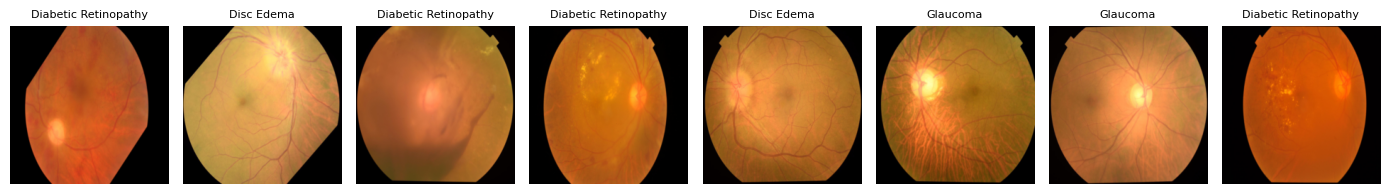

In [4]:
# Show a few images, like the sample notebook does after loading data.
fig, axes = plt.subplots(1, min(8, len(display_subset)), figsize=(14, 2.2))
if len(display_subset) == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    img, label = display_subset[i]
    ax.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    ax.set_title(class_names[label], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 2. Turn each image representation into a graph

The sample notebook converts every 8×8 image into the same fixed grid graph:

- one node per grid location
- edges only between immediate up/down/left/right neighbors
- self loops are added
- the normalized adjacency matrix is reused for every image

Here we use the same method. After the ResNet50 CNN is trained, its last convolutional feature map has shape `2048 × 7 × 7` for a 224×224 input. Each 7×7 location becomes a graph node, and the node feature is the 2048-dimensional ResNet descriptor at that location plus row and column position.


49 nodes, 84 edges


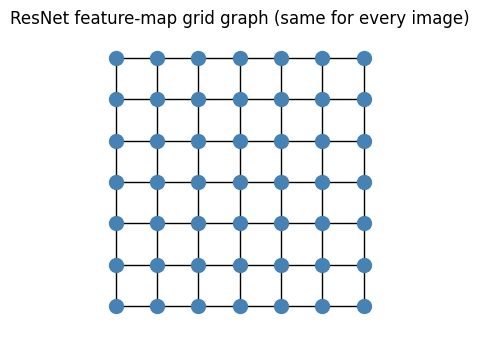

In [5]:
FEATURE_H, FEATURE_W = 7, 7
n_nodes = FEATURE_H * FEATURE_W


def node_id(r, c):
    return r * FEATURE_W + c


G = nx.Graph()
G.add_nodes_from(range(n_nodes))
for r in range(FEATURE_H):
    for c in range(FEATURE_W):
        if r + 1 < FEATURE_H:
            G.add_edge(node_id(r, c), node_id(r + 1, c))
        if c + 1 < FEATURE_W:
            G.add_edge(node_id(r, c), node_id(r, c + 1))

A = nx.to_numpy_array(G)
A_tilde = A + np.eye(n_nodes)                       # add self-loops
D_inv_sqrt = np.diag(1.0 / np.sqrt(A_tilde.sum(axis=1)))
A_hat = torch.tensor(D_inv_sqrt @ A_tilde @ D_inv_sqrt, dtype=torch.float32).to(device)

print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

pos = {node_id(r, c): (c, -r) for r in range(FEATURE_H) for c in range(FEATURE_W)}
plt.figure(figsize=(3, 3))
nx.draw(G, pos, node_size=100, node_color="steelblue")
plt.title("ResNet feature-map grid graph (same for every image)")
plt.show()


## 3. Node features

The sample notebook uses `[pixel intensity, row, col]` as node features. We keep that same idea, but replace raw pixel intensity with the trained ResNet50 deep feature vector at each 7×7 grid location:

`[resnet_feature_1, ..., resnet_feature_2048, row, col]`


In [6]:
row_pos = np.array([r for r in range(FEATURE_H) for c in range(FEATURE_W)]) / FEATURE_H
col_pos = np.array([c for r in range(FEATURE_H) for c in range(FEATURE_W)]) / FEATURE_W
pos_features = torch.tensor(np.stack([row_pos, col_pos], axis=1), dtype=torch.float32)


def make_features(feature_maps):
    '''
    feature_maps: (n_images, channels, 7, 7)
    returns:      (n_images, 49, channels + 2) = [deep features, row, col]
    '''
    if isinstance(feature_maps, np.ndarray):
        feature_maps = torch.tensor(feature_maps, dtype=torch.float32)

    n, channels, h, w = feature_maps.shape
    assert h == FEATURE_H and w == FEATURE_W, f"Expected {FEATURE_H}x{FEATURE_W}, got {h}x{w}"

    x = feature_maps.permute(0, 2, 3, 1).reshape(n, h * w, channels)
    pos = pos_features.unsqueeze(0).repeat(n, 1, 1)
    return torch.cat([x, pos], dim=-1)


## 4. Build and train the CNN baseline: pretrained ResNet50

In [7]:
def build_resnet50_classifier(num_classes):
    weights = ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


cnn_model = build_resnet50_classifier(num_classes).to(device)
print(cnn_model.fc)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 215MB/s]


Linear(in_features=2048, out_features=10, bias=True)


In [8]:
def run_classifier_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    epoch_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for xb, yb in tqdm(loader, leave=False):
            xb = xb.to(device)
            yb = yb.to(device)

            if is_train:
                optimizer.zero_grad()

            out = model(xb)
            loss = criterion(out, yb)

            if is_train:
                loss.backward()
                optimizer.step()

            epoch_loss += loss.item() * xb.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += xb.size(0)

    return epoch_loss / total, correct / total


criterion = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

cnn_history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

start_train = time.perf_counter()
for epoch in range(CNN_EPOCHS):
    train_loss, train_acc = run_classifier_epoch(cnn_model, train_loader, criterion, cnn_optimizer)
    test_loss, test_acc = run_classifier_epoch(cnn_model, test_loader, criterion)

    cnn_history["train_loss"].append(train_loss)
    cnn_history["train_acc"].append(train_acc)
    cnn_history["test_loss"].append(test_loss)
    cnn_history["test_acc"].append(test_acc)

    print(
        f"Epoch {epoch + 1:02d}/{CNN_EPOCHS} | "
        f"train loss {train_loss:.4f} | train acc {train_acc:.3f} | "
        f"test loss {test_loss:.4f} | test acc {test_acc:.3f}"
    )

cnn_train_time = time.perf_counter() - start_train
print(f"ResNet50 training time: {cnn_train_time:.2f} seconds")


  0%|          | 0/407 [00:00<?, ?it/s]

  0%|          | 0/102 [00:00<?, ?it/s]

Epoch 01/20 | train loss 0.8043 | train acc 0.720 | test loss 0.4619 | test acc 0.833


  0%|          | 0/407 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

...

Epoch 19/20 | train loss 0.1314 | train acc 0.933 | test loss 0.2284 | test acc 0.902


  0%|          | 0/407 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

  0%|          | 0/102 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.1210 | train acc 0.937 | test loss 0.2317 | test acc 0.904
ResNet50 training time: 7402.44 seconds


In [9]:
def collect_classifier_predictions(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    start_test = time.perf_counter()
    with torch.no_grad():
        for xb, yb in tqdm(loader, leave=False):
            xb = xb.to(device)
            out = model(xb)
            prob = F.softmax(out, dim=1)

            y_true.extend(yb.numpy().tolist())
            y_pred.extend(prob.argmax(dim=1).cpu().numpy().tolist())
            y_prob.extend(prob.cpu().numpy())

    test_time = time.perf_counter() - start_test
    return np.array(y_true), np.array(y_pred), np.array(y_prob), test_time


cnn_y_true, cnn_y_pred, cnn_y_prob, cnn_test_time = collect_classifier_predictions(cnn_model, test_loader)
print(f"ResNet50 testing time: {cnn_test_time:.2f} seconds")


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

  0%|          | 0/102 [00:03<?, ?it/s]

^assert self._parent_pid == os.getpid(), 'can only test a child process'^^^
^ ^ ^^ ^ ^ ^ ^ ^^ ^  ^ ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
^AssertionError^: ^can only test a child process^
^^^Exception ignored in: ^^<function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>^
^Traceback (most recent call last):
^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^    ^self._shutdown_workers()^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^
    AssertionError: if w.is_alive():can only test a child process

       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7998384867a0>
Traceback (most r

ResNet50 testing time: 77.03 seconds


## 5. Extract ResNet50 deep features

In [10]:
class ResNet50FeatureExtractor(nn.Module):
    '''Return the final convolutional feature map before global pooling.'''
    def __init__(self, trained_resnet):
        super().__init__()
        self.features = nn.Sequential(*list(trained_resnet.children())[:-2])

    def forward(self, x):
        return self.features(x)


feature_extractor = ResNet50FeatureExtractor(cnn_model).to(device)
feature_extractor.eval()


def extract_feature_maps(loader):
    all_features, all_labels = [], []
    start = time.perf_counter()
    with torch.no_grad():
        for xb, yb in tqdm(loader):
            xb = xb.to(device)
            fmap = feature_extractor(xb).cpu()
            all_features.append(fmap)
            all_labels.append(yb)
    elapsed = time.perf_counter() - start
    return torch.cat(all_features, dim=0), torch.cat(all_labels, dim=0), elapsed


train_feature_maps, y_train, train_feature_time = extract_feature_maps(train_loader)
test_feature_maps, y_test, test_feature_time = extract_feature_maps(test_loader)

X_train = make_features(train_feature_maps)
X_test = make_features(test_feature_maps)
y_train = y_train.long()
y_test = y_test.long()

print("Train graph features:", X_train.shape)
print("Test graph features:", X_test.shape)
print(f"Feature extraction time: train {train_feature_time:.2f}s | test {test_feature_time:.2f}s")


  0%|          | 0/407 [00:00<?, ?it/s]

  0%|          | 0/102 [00:00<?, ?it/s]

Train graph features: torch.Size([12993, 49, 2050])
Test graph features: torch.Size([3249, 49, 2050])
Feature extraction time: train 253.47s | test 60.18s


## 6. Build GNN models

All four models receive the same graph input:

- `A_hat`: normalized 4-neighbor grid adjacency from the sample notebook method
- `X`: node features from ResNet50 feature maps plus row/column position

The models differ only in their message-passing block:

- **MDGNet**: multi-depth dense GCN aggregation
- **ViG / Visual GNN**: visual graph block with residual graph convolution and feed-forward layers
- **GATv2**: dense GATv2-style dynamic attention over the same fixed grid edges
- **SuperGAT**: GAT-style attention with an auxiliary edge-supervision loss over existing and sampled non-existing grid edges


In [11]:
class GCNLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, A_hat, H):
        H = self.linear(H)                          # transform
        H = torch.einsum("ij,bjf->bif", A_hat, H)    # aggregate over neighbors
        return H


class MDGNet(nn.Module):
    '''Multi-depth graph network using the same normalized grid adjacency.'''
    def __init__(self, in_features, hidden=128, num_classes=10, dropout=0.25):
        super().__init__()
        self.input = nn.Linear(in_features, hidden)
        self.layer1 = GCNLayer(hidden, hidden)
        self.layer2 = GCNLayer(hidden, hidden)
        self.layer3 = GCNLayer(hidden, hidden)
        self.fuse = nn.Linear(hidden * 3, hidden)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, A_hat, X, return_aux=False):
        h0 = F.relu(self.input(X))
        h1 = F.relu(self.layer1(A_hat, h0))
        h2 = F.relu(self.layer2(A_hat, h1))
        h3 = F.relu(self.layer3(A_hat, h2))
        h = self.fuse(torch.cat([h1, h2, h3], dim=-1))
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, None) if return_aux else logits


class ViGBlock(nn.Module):
    def __init__(self, hidden, dropout=0.25):
        super().__init__()
        self.graph = GCNLayer(hidden, hidden)
        self.norm1 = nn.LayerNorm(hidden)
        self.ffn = nn.Sequential(
            nn.Linear(hidden, hidden * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden * 2, hidden),
        )
        self.norm2 = nn.LayerNorm(hidden)

    def forward(self, A_hat, x):
        x = self.norm1(x + F.gelu(self.graph(A_hat, x)))
        x = self.norm2(x + self.ffn(x))
        return x


class VisualGNN(nn.Module):
    def __init__(self, in_features, hidden=128, num_classes=10, depth=4, dropout=0.25):
        super().__init__()
        self.input = nn.Linear(in_features, hidden)
        self.blocks = nn.ModuleList([ViGBlock(hidden, dropout) for _ in range(depth)])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, A_hat, X, return_aux=False):
        h = F.gelu(self.input(X))
        for block in self.blocks:
            h = block(A_hat, h)
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, None) if return_aux else logits


class DenseGATv2Layer(nn.Module):
    def __init__(self, in_features, out_features, heads=4, dropout=0.20):
        super().__init__()
        assert out_features % heads == 0
        self.heads = heads
        self.head_dim = out_features // heads
        self.lin_l = nn.Linear(in_features, out_features, bias=False)
        self.lin_r = nn.Linear(in_features, out_features, bias=False)
        self.att = nn.Parameter(torch.empty(heads, self.head_dim))
        self.bias = nn.Parameter(torch.zeros(out_features))
        self.dropout = nn.Dropout(dropout)
        nn.init.xavier_uniform_(self.att)

    def forward(self, A_hat, X, return_attention=False):
        B, N, _ = X.shape
        left = self.lin_l(X).view(B, N, self.heads, self.head_dim)
        right = self.lin_r(X).view(B, N, self.heads, self.head_dim)
        pair = torch.tanh(left.unsqueeze(2) + right.unsqueeze(1))
        scores = (pair * self.att.view(1, 1, 1, self.heads, self.head_dim)).sum(dim=-1)

        edge_mask = A_hat > 0
        scores = scores.masked_fill(~edge_mask.view(1, N, N, 1), -9e15)
        alpha = F.softmax(scores, dim=2)
        alpha = self.dropout(alpha)
        out = torch.einsum("bijh,bjhd->bihd", alpha, right)
        out = out.reshape(B, N, self.heads * self.head_dim) + self.bias
        return (out, alpha) if return_attention else out


class GATv2Net(nn.Module):
    def __init__(self, in_features, hidden=128, num_classes=10, heads=4, dropout=0.25):
        super().__init__()
        self.layer1 = DenseGATv2Layer(in_features, hidden, heads=heads, dropout=dropout)
        self.layer2 = DenseGATv2Layer(hidden, hidden, heads=heads, dropout=dropout)
        self.layer3 = DenseGATv2Layer(hidden, hidden, heads=heads, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, A_hat, X, return_aux=False):
        h = F.elu(self.layer1(A_hat, X))
        h = F.elu(self.layer2(A_hat, h))
        h = F.elu(self.layer3(A_hat, h))
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, None) if return_aux else logits


class SuperGATNet(nn.Module):
    def __init__(self, in_features, hidden=128, num_classes=10, heads=4, dropout=0.25, aux_weight=0.10):
        super().__init__()
        self.layer1 = DenseGATv2Layer(in_features, hidden, heads=heads, dropout=dropout)
        self.layer2 = DenseGATv2Layer(hidden, hidden, heads=heads, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)
        self.aux_weight = aux_weight

    def attention_supervision_loss(self, alpha, A_hat):
        # SuperGAT-style auxiliary supervision: attention should be high on true grid edges
        # and low on sampled non-edges. This keeps the graph conversion method unchanged.
        edge_target = (A_hat > 0).float()
        edge_target = edge_target.unsqueeze(0).unsqueeze(-1).expand_as(alpha)

        non_edge_mask = (A_hat == 0).unsqueeze(0).unsqueeze(-1).expand_as(alpha)
        edge_mask = (A_hat > 0).unsqueeze(0).unsqueeze(-1).expand_as(alpha)

        sampled_non_edges = non_edge_mask & (torch.rand_like(alpha) < 0.10)
        supervised_mask = edge_mask | sampled_non_edges

        if supervised_mask.sum() == 0:
            return alpha.new_tensor(0.0)

        logits = torch.logit(alpha.clamp(1e-5, 1 - 1e-5))
        return F.binary_cross_entropy_with_logits(logits[supervised_mask], edge_target[supervised_mask])

    def forward(self, A_hat, X, return_aux=False):
        h, alpha = self.layer1(A_hat, X, return_attention=True)
        aux_loss = self.attention_supervision_loss(alpha, A_hat)
        h = F.elu(h)
        h = F.elu(self.layer2(A_hat, h))
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, self.aux_weight * aux_loss) if return_aux else logits


in_features = X_train.shape[-1]
gnn_models = {
    "MDGNet": MDGNet(in_features, hidden=128, num_classes=num_classes),
    "ViG_Visual_GNN": VisualGNN(in_features, hidden=128, num_classes=num_classes),
    "GATv2": GATv2Net(in_features, hidden=128, num_classes=num_classes),
    "SuperGAT": SuperGATNet(in_features, hidden=128, num_classes=num_classes),
}

for name, model in gnn_models.items():
    print(name, "parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


MDGNet parameters: 362634
ViG_Visual_GNN parameters: 595594
GATv2 parameters: 592394
SuperGAT parameters: 559370


## 7. Train the GNN models

In [12]:
def batch_iter(X, y, batch_size=64, shuffle=True):
    n = X.shape[0]
    perm = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        idx = perm[start:start + batch_size]
        yield X[idx], y[idx]


def evaluate_gnn(model, A_hat, X, y, criterion, batch_size=64):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total = 0
    probs, preds, labels = [], [], []

    start_test = time.perf_counter()
    with torch.no_grad():
        for xb, yb in batch_iter(X, y, batch_size=batch_size, shuffle=False):
            xb = xb.to(device)
            yb = yb.to(device)
            logits = model(A_hat, xb)
            loss = criterion(logits, yb)
            prob = F.softmax(logits, dim=1)
            pred = prob.argmax(dim=1)

            total_loss += loss.item() * xb.size(0)
            total_correct += (pred == yb).sum().item()
            total += xb.size(0)

            probs.append(prob.cpu())
            preds.append(pred.cpu())
            labels.append(yb.cpu())

    test_time = time.perf_counter() - start_test
    return {
        "loss": total_loss / total,
        "acc": total_correct / total,
        "y_true": torch.cat(labels).numpy(),
        "y_pred": torch.cat(preds).numpy(),
        "y_prob": torch.cat(probs).numpy(),
        "test_time": test_time,
    }


def train_gnn_model(model, name, A_hat, X_train, y_train, X_test, y_test, epochs=20, batch_size=64):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=GNN_LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    X_train_cpu = X_train.float()
    X_test_cpu = X_test.float()
    y_train_cpu = y_train.long()
    y_test_cpu = y_test.long()

    start_train = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in batch_iter(X_train_cpu, y_train_cpu, batch_size=batch_size, shuffle=True):
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits, aux_loss = model(A_hat, xb, return_aux=True)
            loss = criterion(logits, yb)
            if aux_loss is not None:
                loss = loss + aux_loss
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * xb.size(0)
            pred = logits.argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += xb.size(0)

        train_loss = epoch_loss / total
        train_acc = correct / total
        test_eval = evaluate_gnn(model, A_hat, X_test_cpu, y_test_cpu, criterion, batch_size=batch_size)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_eval["loss"])
        history["test_acc"].append(test_eval["acc"])

        print(
            f"{name} | Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss {train_loss:.4f} | train acc {train_acc:.3f} | "
            f"test loss {test_eval['loss']:.4f} | test acc {test_eval['acc']:.3f}"
        )

    train_time = time.perf_counter() - start_train
    final_eval = evaluate_gnn(model, A_hat, X_test_cpu, y_test_cpu, criterion, batch_size=batch_size)
    final_eval["train_time"] = train_time
    final_eval["history"] = history
    return model, final_eval


gnn_results = {}
trained_gnn_models = {}

for name, model in gnn_models.items():
    print("\n" + "=" * 80)
    print("Training", name)
    print("=" * 80)
    trained_model, result = train_gnn_model(
        model, name, A_hat, X_train, y_train, X_test, y_test,
        epochs=GNN_EPOCHS,
        batch_size=64,
    )
    trained_gnn_models[name] = trained_model
    gnn_results[name] = result
    print(f"{name} training time: {result['train_time']:.2f}s | testing time: {result['test_time']:.2f}s")



Training MDGNet
MDGNet | Epoch 01/20 | train loss 0.2836 | train acc 0.899 | test loss 0.2323 | test acc 0.909
MDGNet | Epoch 02/20 | train loss 0.1176 | train acc 0.942 | test loss 0.2313 | test acc 0.908
MDGNet | Epoch 03/20 | train loss 0.1136 | train acc 0.942 | test loss 0.2774 | test acc 0.907
MDGNet | Epoch 04/20 | train loss 0.1170 | train acc 0.942 | test loss 0.2500 | test acc 0.905
MDGNet | Epoch 05/20 | train loss 0.1040 | train acc 0.944 | test loss 0.2427 | test acc 0.902
MDGNet | Epoch 06/20 | train loss 0.1011 | train acc 0.947 | test loss 0.2614 | test acc 0.906
MDGNet | Epoch 07/20 | train loss 0.1001 | train acc 0.949 | test loss 0.2553 | test acc 0.906
MDGNet | Epoch 08/20 | train loss 0.0962 | train acc 0.948 | test loss 0.2689 | test acc 0.910
MDGNet | Epoch 09/20 | train loss 0.1040 | train acc 0.949 | test loss 0.2677 | test acc 0.908
MDGNet | Epoch 10/20 | train loss 0.0931 | train acc 0.950 | test loss 0.2667 | test acc 0.906
MDGNet | Epoch 11/20 | train loss

## 8. Results and evaluation outputs

In [13]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["test_loss"], label="test")
    axes[0].set_title(f"{title} loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["test_acc"], label="test")
    axes[1].set_title(f"{title} accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="True label",
        xlabel="Predicted label",
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor", fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)

    thresh = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_roc_curves(y_true, y_prob, title):
    y_bin = label_binarize(y_true, classes=np.arange(num_classes))
    fig, ax = plt.subplots(figsize=(8, 7))

    auc_values = []
    for i in range(num_classes):
        if y_bin[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        auc_values.append(roc_auc)
        ax.plot(fpr, tpr, lw=1.5, label=f"{class_names[i]} (AUC={roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=7)
    plt.tight_layout()
    plt.show()

    try:
        macro_auc = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")
    except ValueError:
        macro_auc = float("nan")
    return macro_auc


def display_full_evaluation(name, y_true, y_pred, y_prob, history=None, train_time=None, test_time=None):
    if history is not None:
        plot_history(history, name)

    overall_acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
    per_class_acc = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(num_classes), zero_division=0
    )

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)
    print(f"Overall report accuracy: {overall_acc:.4f}")
    if train_time is not None:
        print(f"Training time: {train_time:.2f} seconds")
    if test_time is not None:
        print(f"Testing time: {test_time:.2f} seconds")

    print("\nPer-class accuracy / precision / recall / F1-score")
    for i, cls in enumerate(class_names):
        print(
            f"{cls:55s} | "
            f"acc {per_class_acc[i]:.4f} | "
            f"precision {precision[i]:.4f} | "
            f"recall {recall[i]:.4f} | "
            f"F1 {f1[i]:.4f} | "
            f"support {support[i]}"
        )

    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    plot_confusion_matrix(cm, f"{name} confusion matrix")
    macro_auc = plot_roc_curves(y_true, y_prob, f"{name} ROC curves")
    print(f"Macro AUC (one-vs-rest): {macro_auc:.4f}")
    return {
        "accuracy": overall_acc,
        "macro_auc": macro_auc,
        "train_time": train_time,
        "test_time": test_time,
    }


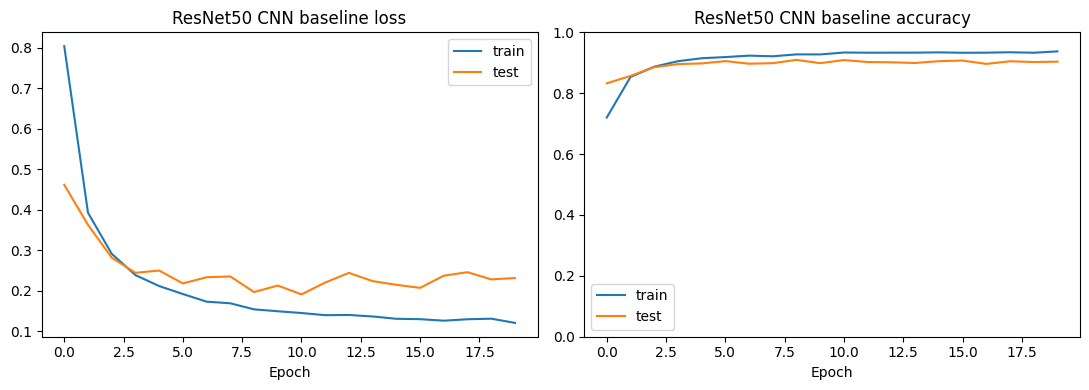


ResNet50 CNN baseline
Overall report accuracy: 0.9037
Training time: 7402.44 seconds
Testing time: 77.03 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.9174 | precision 0.8473 | recall 0.9174 | F1 0.8810 | support 121
Diabetic Retinopathy                                    | acc 0.9637 | precision 0.9852 | recall 0.9637 | F1 0.9743 | support 689
Disc Edema                                              | acc 0.9804 | precision 0.9375 | recall 0.9804 | F1 0.9585 | support 153
Glaucoma                                                | acc 0.8819 | precision 0.7975 | recall 0.8819 | F1 0.8376 | support 576
Healthy                                                 | acc 0.8411 | precision 0.9165 | recall 0.8411 | F1 0.8772 | support 535
Macular Scar                                            | acc 0.8557 | precision 0.9022 | recall 0.8557 | F1 0.8783 | support 388
Myopia                                                

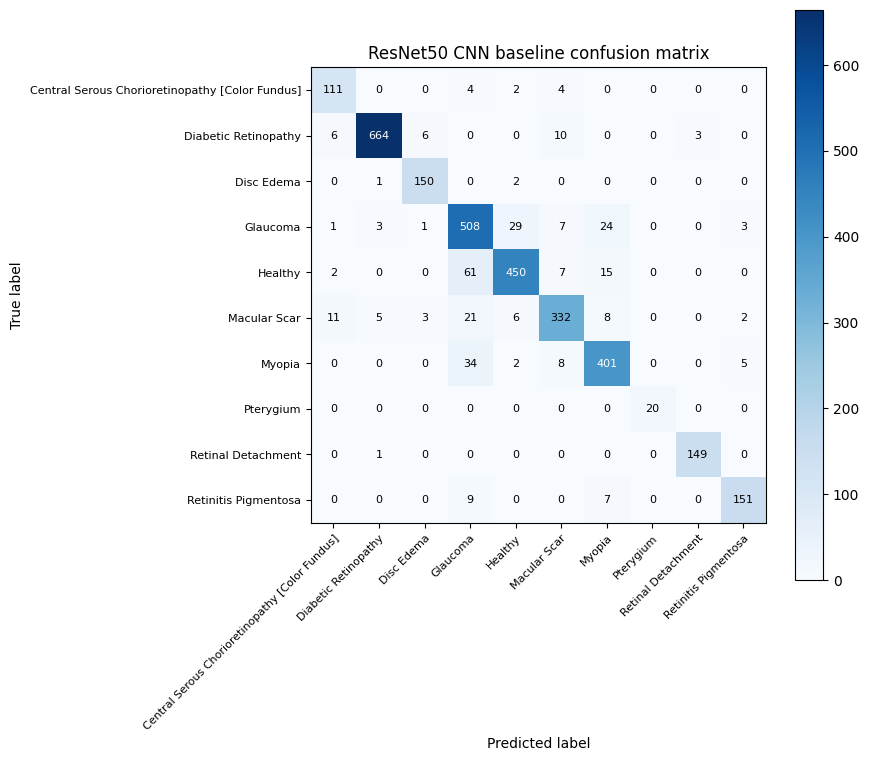

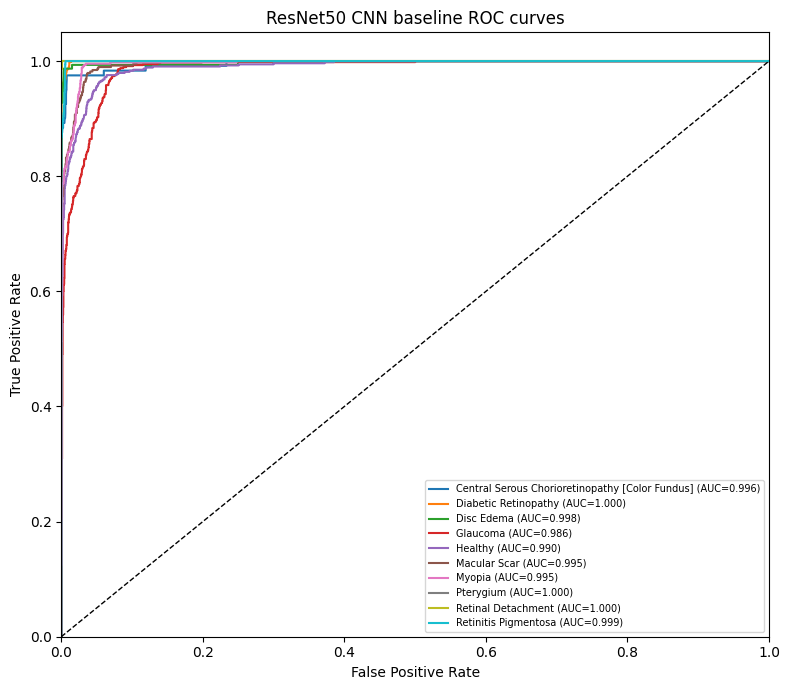

Macro AUC (one-vs-rest): 0.9959


In [14]:
# CNN baseline evaluation
cnn_summary = display_full_evaluation(
    "ResNet50 CNN baseline",
    cnn_y_true,
    cnn_y_pred,
    cnn_y_prob,
    history=cnn_history,
    train_time=cnn_train_time,
    test_time=cnn_test_time,
)


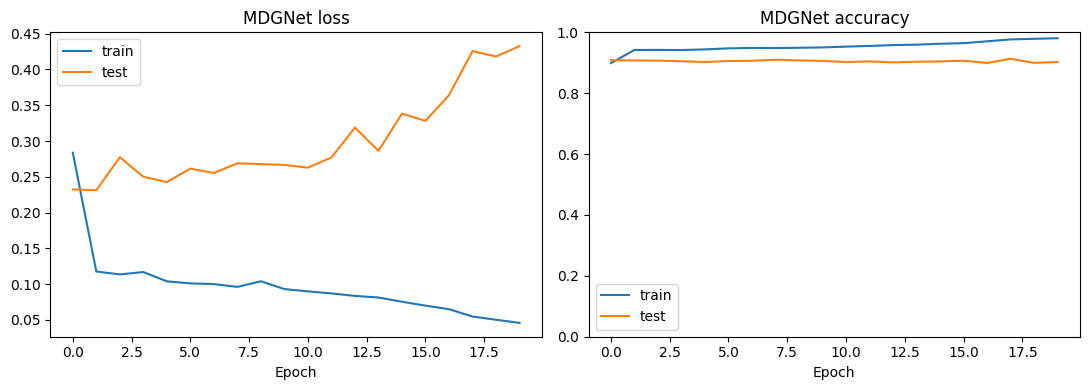


MDGNet
Overall report accuracy: 0.9024
Training time: 64.06 seconds
Testing time: 0.69 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.8926 | precision 0.8710 | recall 0.8926 | F1 0.8816 | support 121
Diabetic Retinopathy                                    | acc 0.9855 | precision 0.9631 | recall 0.9855 | F1 0.9742 | support 689
Disc Edema                                              | acc 0.9412 | precision 0.9931 | recall 0.9412 | F1 0.9664 | support 153
Glaucoma                                                | acc 0.8594 | precision 0.7997 | recall 0.8594 | F1 0.8285 | support 576
Healthy                                                 | acc 0.8636 | precision 0.9059 | recall 0.8636 | F1 0.8842 | support 535
Macular Scar                                            | acc 0.8557 | precision 0.9121 | recall 0.8557 | F1 0.8830 | support 388
Myopia                                                  | acc 0.8711 | p

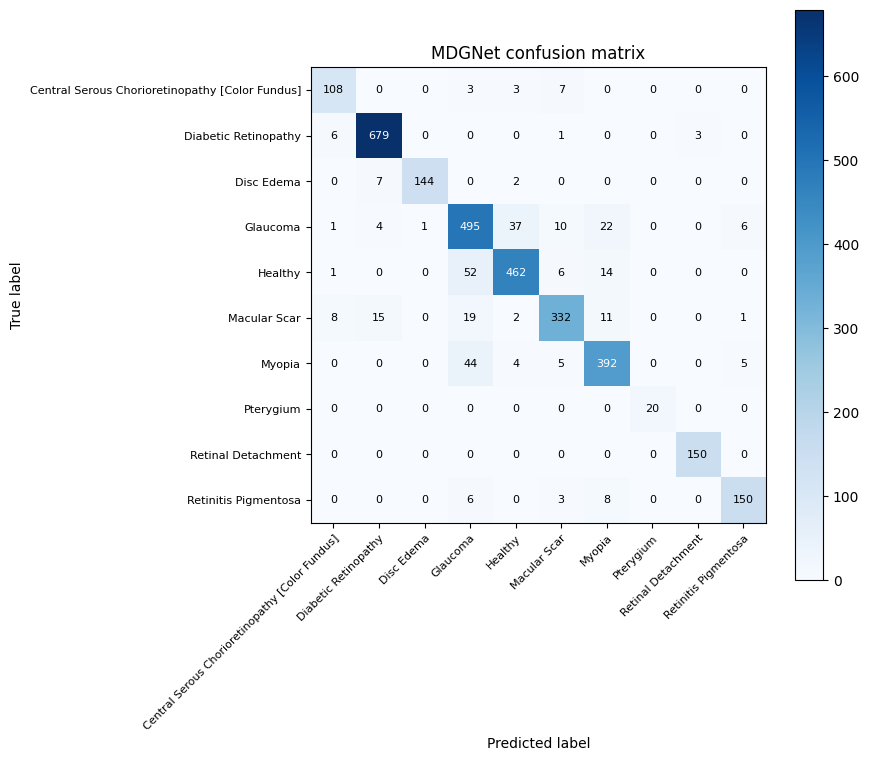

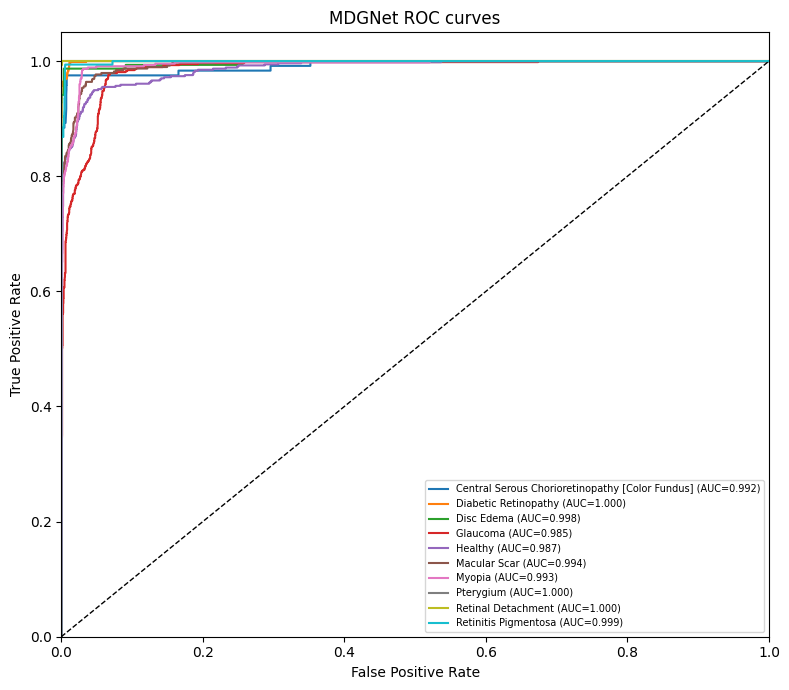

Macro AUC (one-vs-rest): 0.9948


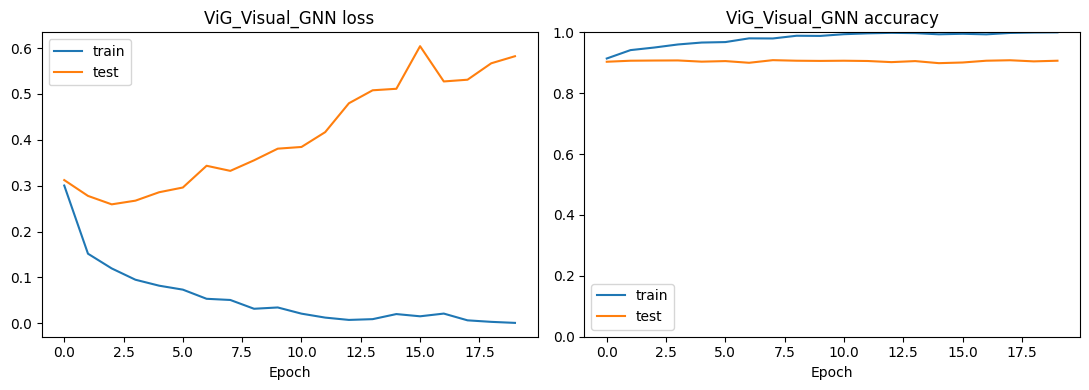


ViG_Visual_GNN
Overall report accuracy: 0.9067
Training time: 77.90 seconds
Testing time: 0.57 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.8760 | precision 0.8689 | recall 0.8760 | F1 0.8724 | support 121
Diabetic Retinopathy                                    | acc 0.9782 | precision 0.9726 | recall 0.9782 | F1 0.9754 | support 689
Disc Edema                                              | acc 0.9412 | precision 0.9600 | recall 0.9412 | F1 0.9505 | support 153
Glaucoma                                                | acc 0.8628 | precision 0.8161 | recall 0.8628 | F1 0.8388 | support 576
Healthy                                                 | acc 0.8617 | precision 0.9075 | recall 0.8617 | F1 0.8840 | support 535
Macular Scar                                            | acc 0.8660 | precision 0.9057 | recall 0.8660 | F1 0.8854 | support 388
Myopia                                                  | acc 0.

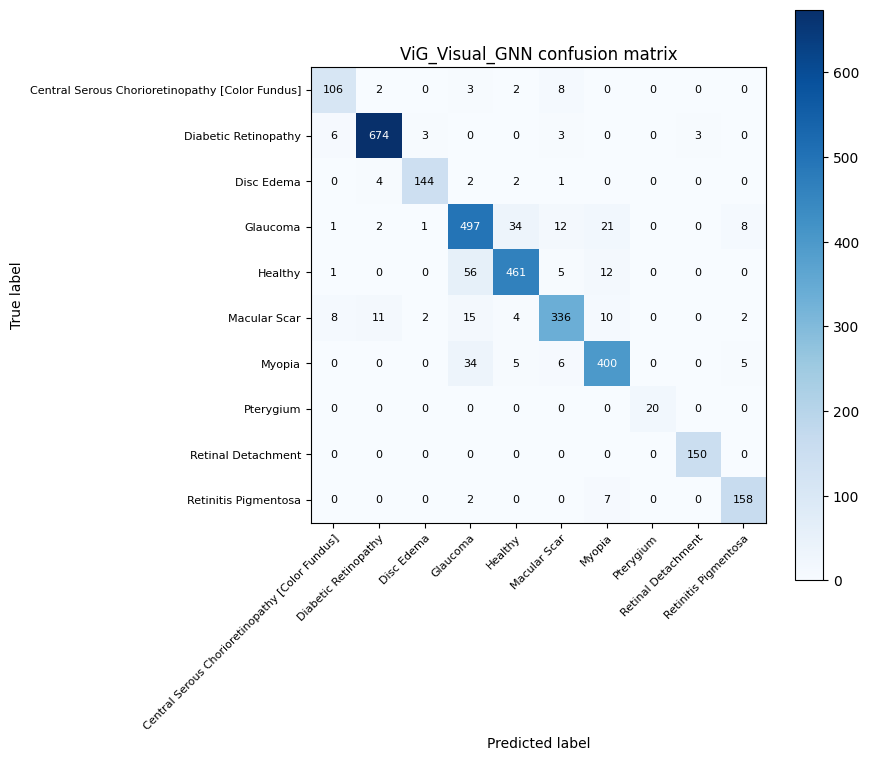

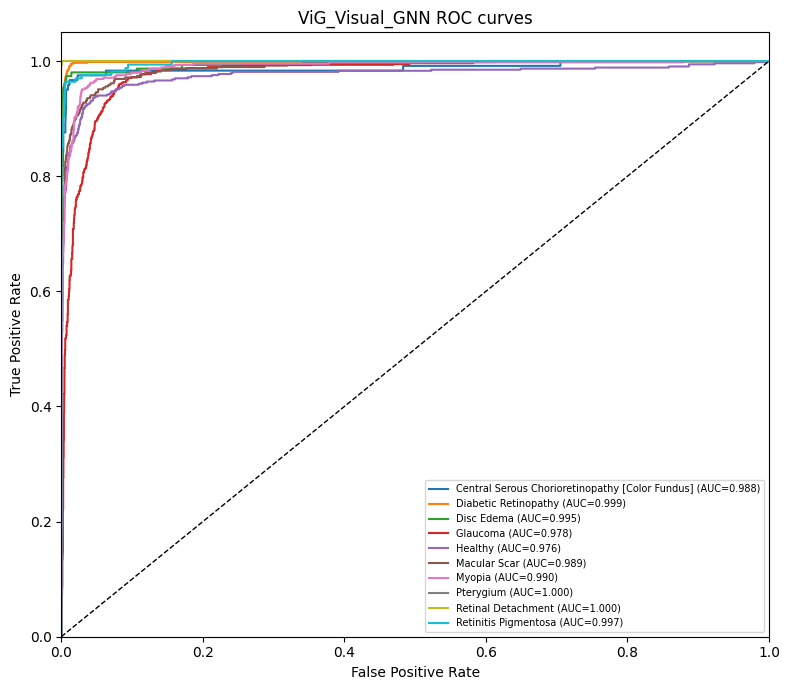

Macro AUC (one-vs-rest): 0.9911


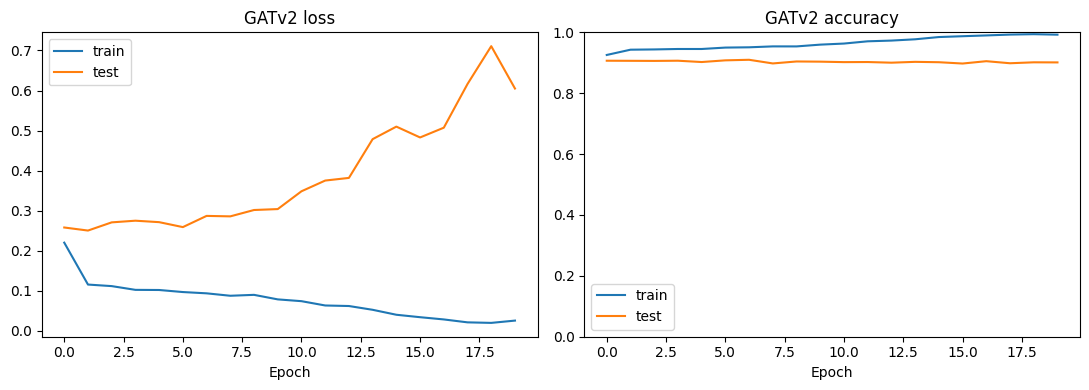


GATv2
Overall report accuracy: 0.9012
Training time: 139.60 seconds
Testing time: 0.92 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.8926 | precision 0.8780 | recall 0.8926 | F1 0.8852 | support 121
Diabetic Retinopathy                                    | acc 0.9753 | precision 0.9669 | recall 0.9753 | F1 0.9711 | support 689
Disc Edema                                              | acc 0.9412 | precision 0.9600 | recall 0.9412 | F1 0.9505 | support 153
Glaucoma                                                | acc 0.8403 | precision 0.8148 | recall 0.8403 | F1 0.8274 | support 576
Healthy                                                 | acc 0.8710 | precision 0.8979 | recall 0.8710 | F1 0.8843 | support 535
Macular Scar                                            | acc 0.8634 | precision 0.8862 | recall 0.8634 | F1 0.8747 | support 388
Myopia                                                  | acc 0.8822 | p

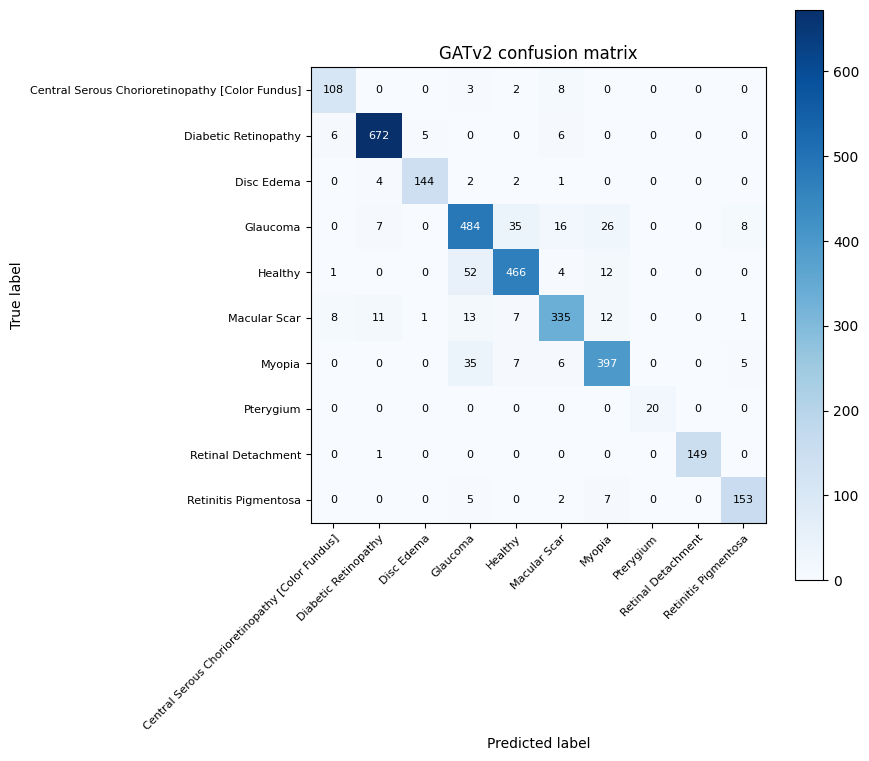

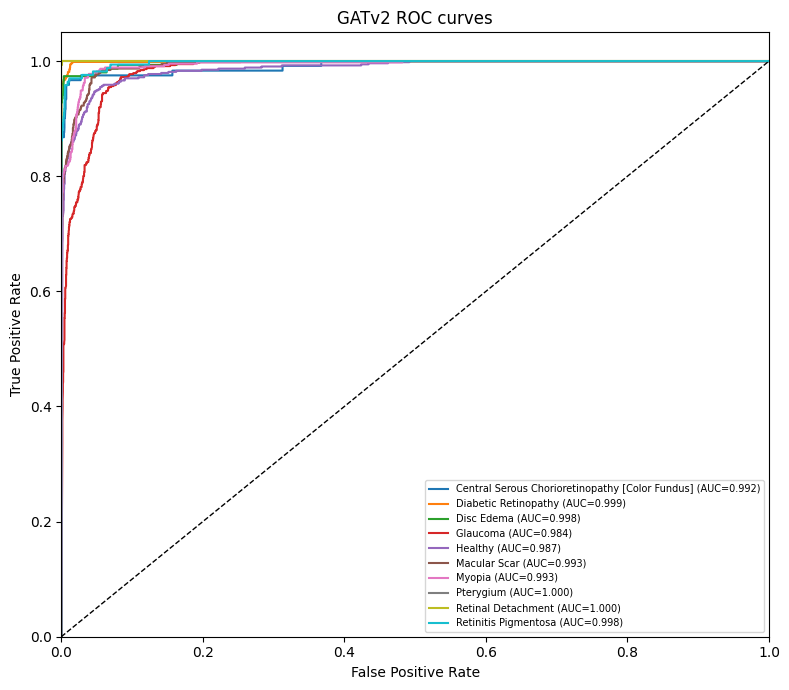

Macro AUC (one-vs-rest): 0.9943


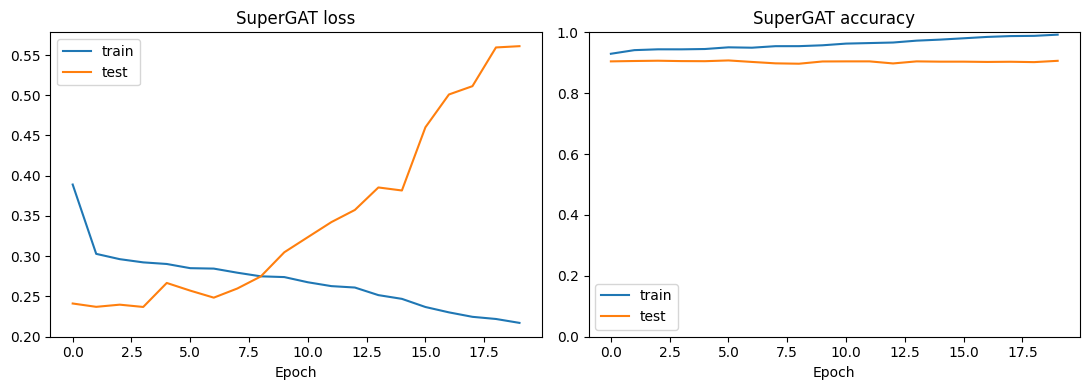


SuperGAT
Overall report accuracy: 0.9064
Training time: 115.99 seconds
Testing time: 0.79 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.9256 | precision 0.8485 | recall 0.9256 | F1 0.8854 | support 121
Diabetic Retinopathy                                    | acc 0.9811 | precision 0.9671 | recall 0.9811 | F1 0.9741 | support 689
Disc Edema                                              | acc 0.9281 | precision 0.9793 | recall 0.9281 | F1 0.9530 | support 153
Glaucoma                                                | acc 0.8872 | precision 0.8035 | recall 0.8872 | F1 0.8432 | support 576
Healthy                                                 | acc 0.8692 | precision 0.9064 | recall 0.8692 | F1 0.8874 | support 535
Macular Scar                                            | acc 0.8479 | precision 0.9242 | recall 0.8479 | F1 0.8844 | support 388
Myopia                                                  | acc 0.8644 

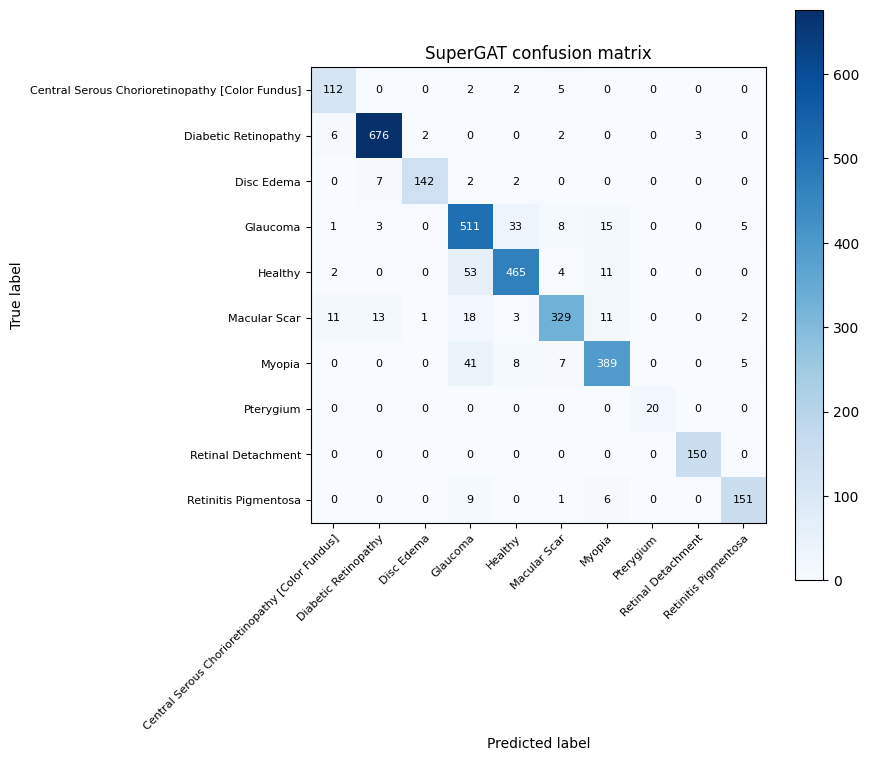

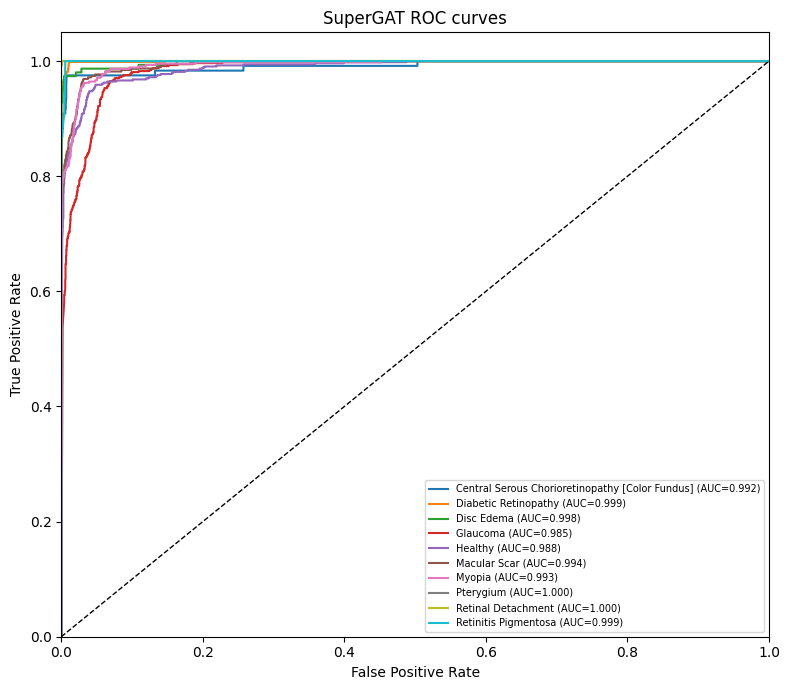

Macro AUC (one-vs-rest): 0.9947


In [15]:
# GNN evaluations
all_model_summaries = {"ResNet50 CNN baseline": cnn_summary}

for name, result in gnn_results.items():
    summary = display_full_evaluation(
        name,
        result["y_true"],
        result["y_pred"],
        result["y_prob"],
        history=result["history"],
        train_time=result["train_time"],
        test_time=result["test_time"],
    )
    all_model_summaries[name] = summary


In [16]:
print("Final summary")
print("=" * 80)
for name, s in all_model_summaries.items():
    print(
        f"{name:25s} | "
        f"accuracy {s['accuracy']:.4f} | "
        f"macro AUC {s['macro_auc']:.4f} | "
        f"train time {s['train_time']:.2f}s | "
        f"test time {s['test_time']:.2f}s"
    )


Final summary
ResNet50 CNN baseline     | accuracy 0.9037 | macro AUC 0.9959 | train time 7402.44s | test time 77.03s
MDGNet                    | accuracy 0.9024 | macro AUC 0.9948 | train time 64.06s | test time 0.69s
ViG_Visual_GNN            | accuracy 0.9067 | macro AUC 0.9911 | train time 77.90s | test time 0.57s
GATv2                     | accuracy 0.9012 | macro AUC 0.9943 | train time 139.60s | test time 0.92s
SuperGAT                  | accuracy 0.9064 | macro AUC 0.9947 | train time 115.99s | test time 0.79s


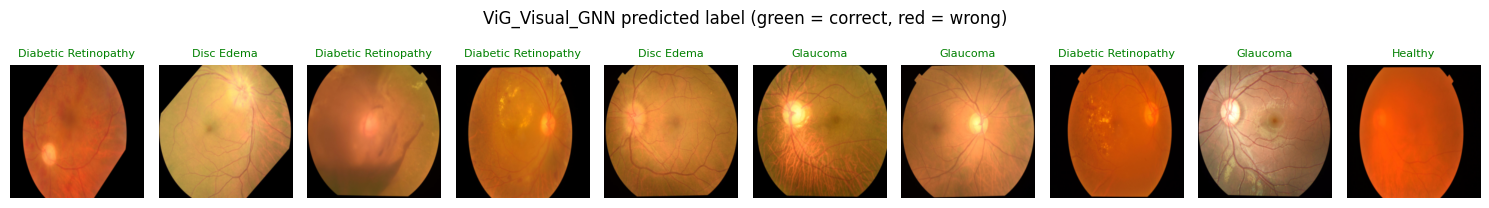

In [17]:
# A few example predictions from the best GNN model.
best_gnn_name = max(gnn_results, key=lambda k: gnn_results[k]["history"]["test_acc"][-1])
best_model = trained_gnn_models[best_gnn_name]
best_model.eval()

with torch.no_grad():
    logits = best_model(A_hat, X_test[:10].float().to(device))
    preds = logits.argmax(dim=1).cpu().numpy()

fig, axes = plt.subplots(1, min(10, len(display_subset)), figsize=(15, 2.2))
if len(display_subset) == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    img, label = display_subset[i]
    ax.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    correct = preds[i] == y_test[i].item()
    ax.set_title(class_names[preds[i]], color="green" if correct else "red", fontsize=8)
    ax.axis("off")

plt.suptitle(f"{best_gnn_name} predicted label (green = correct, red = wrong)")
plt.tight_layout()
plt.show()


## Summary

- The ResNet50 CNN baseline is trained for 20 epochs.
- Deep feature maps are extracted from the trained ResNet50 model.
- Each feature map is converted to a graph with the same method used in the sample notebook: fixed grid nodes, up/down/left/right neighbor edges, self loops, normalized adjacency, and row/column node positions.
- Four GNN models are trained for 20 epochs each: MDGNet, ViG / Visual GNN, GATv2, and SuperGAT.
- For every model, the notebook displays curves, accuracy, per-class accuracy, precision, recall, F1-score, confusion matrix, AUC/ROC, training time, and testing time.
